# Нейросетевые модели стоимости недвижимости и устойчивость к шуму

Завершённый учебный эксперимент на `off_plan.csv`: MLP и TabResNet в сравнении с Ridge,
Random Forest, LightGBM и медианным ориентиром. Две цели обучения: `ln(P)` и `ln(P/A)`.

Основной протокол: train 2021–2023, validation 2024, test 2025–апрель 2026.
Все результаты ниже получены реальным запуском; ноутбук читает сохранённые CSV и модели.
Повторный полный расчёт включается явно в последней ячейке и может занять несколько минут.

Набор рассматривается как учебный с предполагаемым синтетическим происхождением.
Выводы не переносятся на действительный рынок недвижимости без внешней проверки.


In [1]:
from pathlib import Path
import json, sys, subprocess
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'src/core.py').exists():
    if (ROOT / 'dubai_neural_project/src/core.py').exists():
        ROOT = ROOT / 'dubai_neural_project'
    else:
        raise FileNotFoundError('Распакуйте полный ZIP и откройте ноутбук внутри dubai_neural_project')
sys.path.insert(0, str(ROOT / 'src'))
OUT = ROOT / 'outputs'
selection = json.loads((OUT / 'selection_frozen.json').read_text())
print('Общий победитель по validation:', selection['best_overall'])
print('Выбранная нейросеть по validation:', selection['best_neural'])
display(pd.Series(selection['target_per_family'], name='Цель').to_frame())


Общий победитель по validation: LightGBM
Выбранная нейросеть по validation: TabResNet


,Цель
Median,unit
Ridge,total
RandomForest,unit
LightGBM,unit
MLP,unit
TabResNet,total


## Аудит и воспроизводимость
Исходный файл проверяется по SHA-256; статистики предобработки рассчитываются только на train. Ценовые производные и идентификаторы не являются входами.

Объявлений раньше года запуска: 4600
Передача раньше запуска: 66


,n,projects,start,end,median_price
train,6738,172,2021-01-01,2023-12-31,914400.0
val,2278,172,2024-01-01,2024-12-31,1167800.0
test,2984,172,2025-01-01,2026-04-29,1159200.0


,Версия
python,"3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 2..."
platform,Linux-6.18.57-x86_64-with-glibc2.39
numpy,2.5.4
pandas,2.2.3
sklearn,1.8.0
torch,2.6.0+cpu
lightgbm,4.7.0
scipy,1.18.1
torch_threads,2


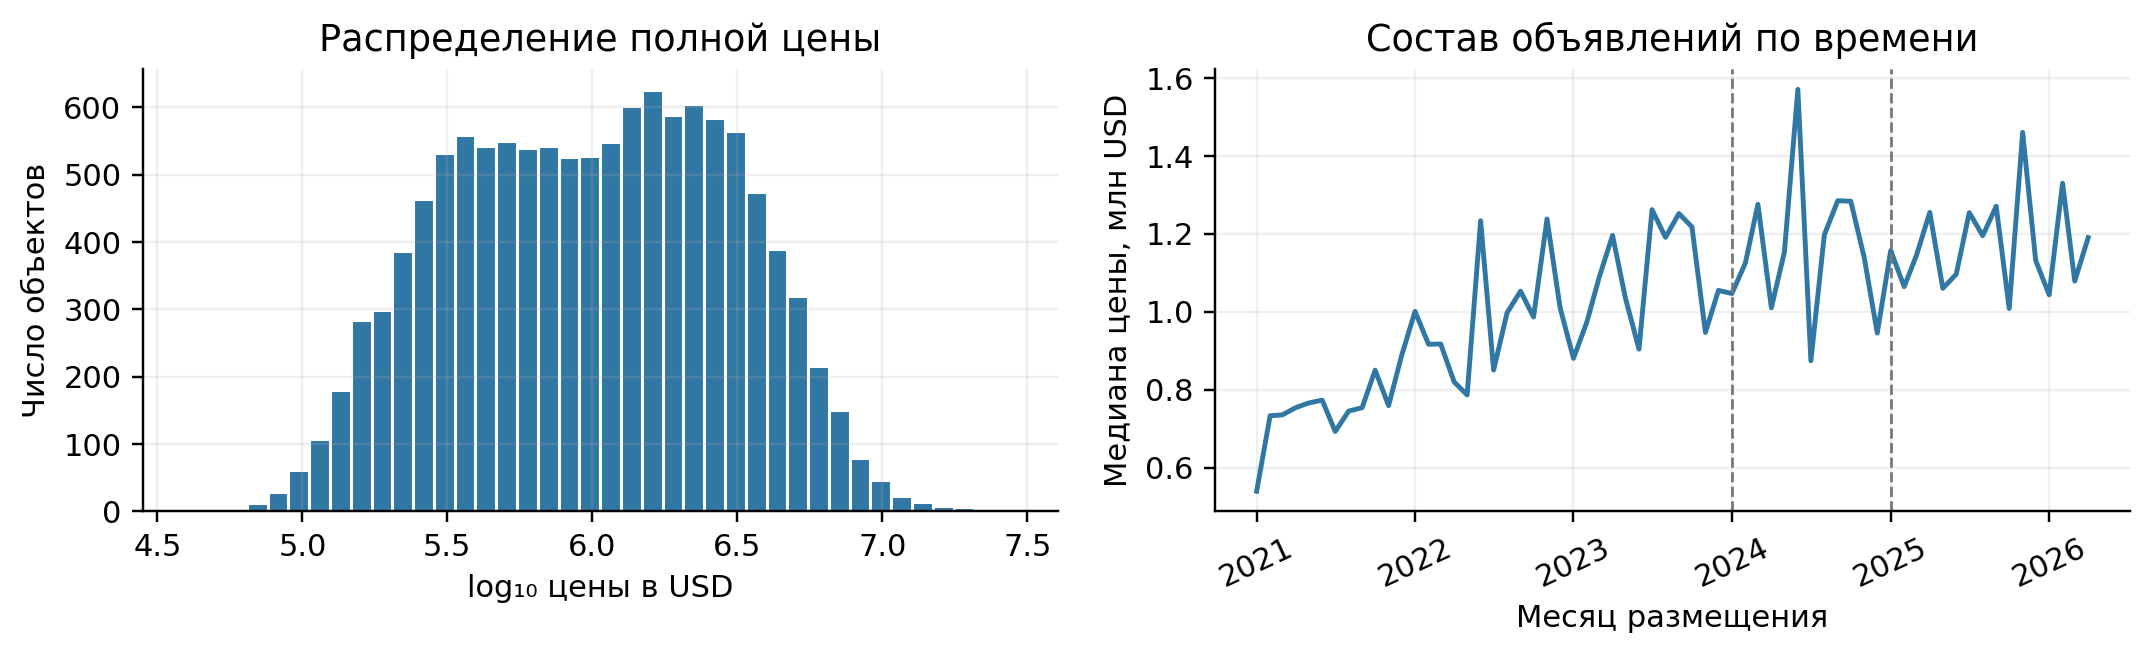

In [2]:
audit = json.loads((OUT / 'data_audit.json').read_text())
display(pd.DataFrame(audit['splits']).T)
print('Объявлений раньше года запуска:', audit['listed_before_launch_year'])
print('Передача раньше запуска:', audit['handover_before_launch_year'])
display(pd.Series(json.loads((OUT / 'environment.json').read_text()), name='Версия').to_frame())
display(Image(filename=str(OUT / 'figures/01_data.png')))


## Итоговый временной тест
Основной seed 42 зафиксирован заранее. Цель внутри каждого семейства выбрана по MAE полной цены на validation. Следующая таблица не выбирает модель по тесту.

,family,target,n,MAE_USD,RMSE_USD,MAPE_pct,R2,within20_pct
5,Median,unit,2984,838104.972,1655494.836,38.932,0.386,25.302
8,Ridge,total,2984,967917.907,1474899.665,58.517,0.512,6.434
17,RandomForest,unit,2984,164764.572,346803.273,8.511,0.973,93.331
23,LightGBM,unit,2984,139891.060,289548.950,7.382,0.981,96.012
35,MLP,unit,2984,534780.649,776266.869,34.983,0.865,20.208
44,TabResNet,total,2984,415240.049,646725.781,30.862,0.906,30.865


,family,target,MAE_USD,RMSE_USD,MAPE_pct,R2
2,Median,total,1383596.549,2326605.289,103.560,-0.213
5,Median,unit,838104.972,1655494.836,38.932,0.386
8,Ridge,total,967917.907,1474899.665,58.517,0.512
11,Ridge,unit,971832.741,1499244.752,57.517,0.496
14,RandomForest,total,275177.218,721842.171,13.642,0.883
17,RandomForest,unit,164764.572,346803.273,8.511,0.973
20,LightGBM,total,163719.736,449751.577,8.361,0.955
23,LightGBM,unit,139891.060,289548.950,7.382,0.981
26,MLP,total,686611.785,1087891.360,38.848,0.735
35,MLP,unit,534780.649,776266.869,34.983,0.865


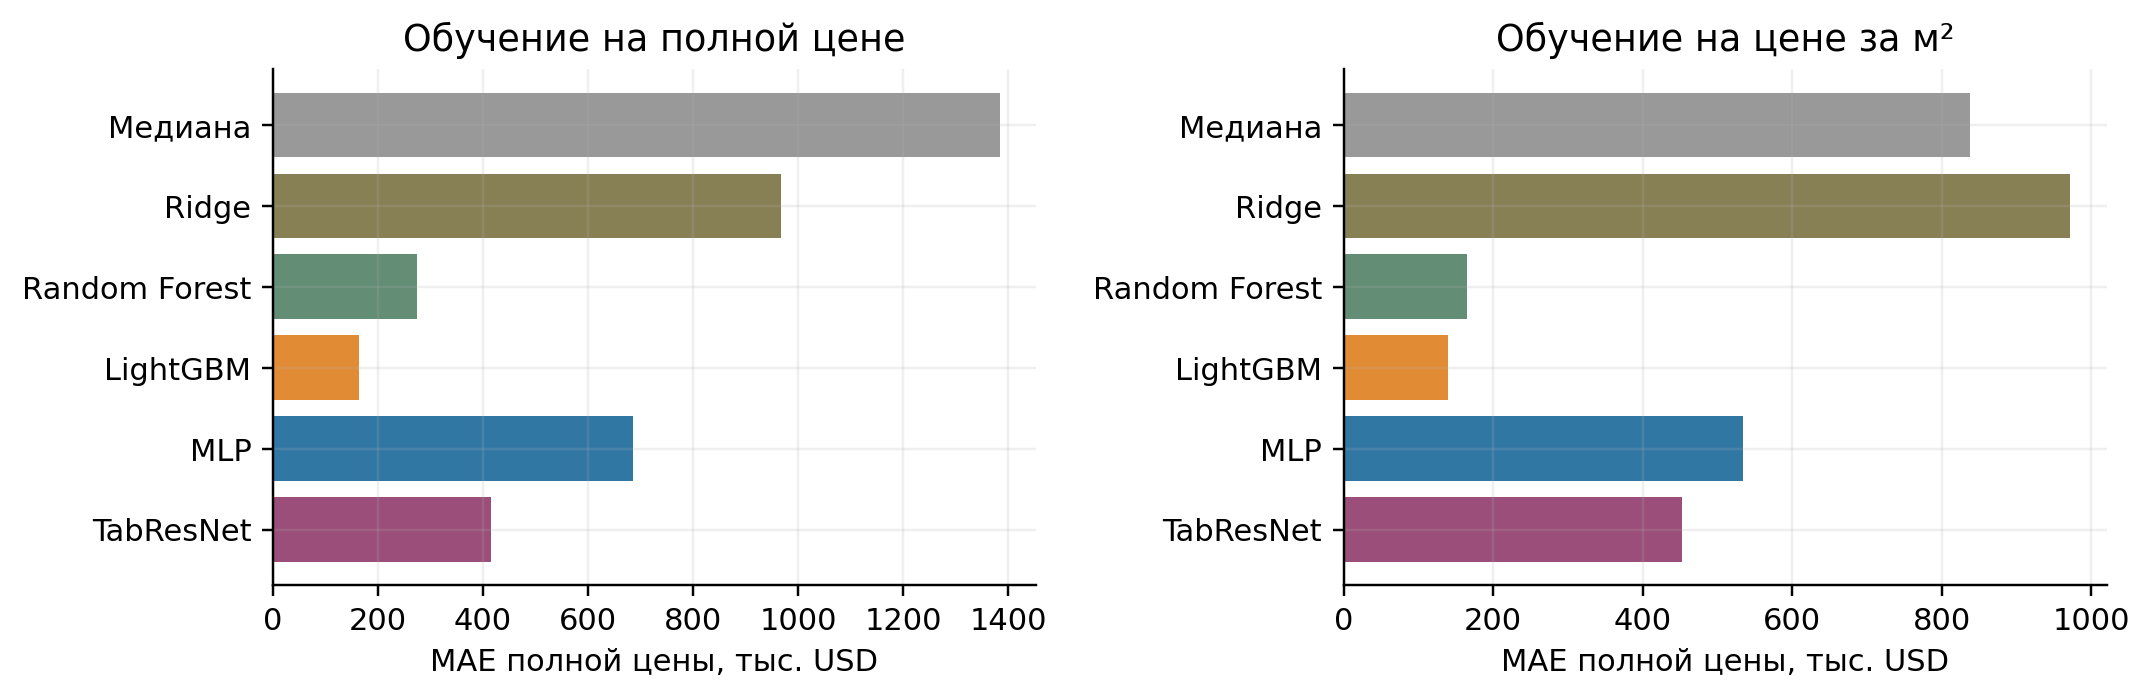

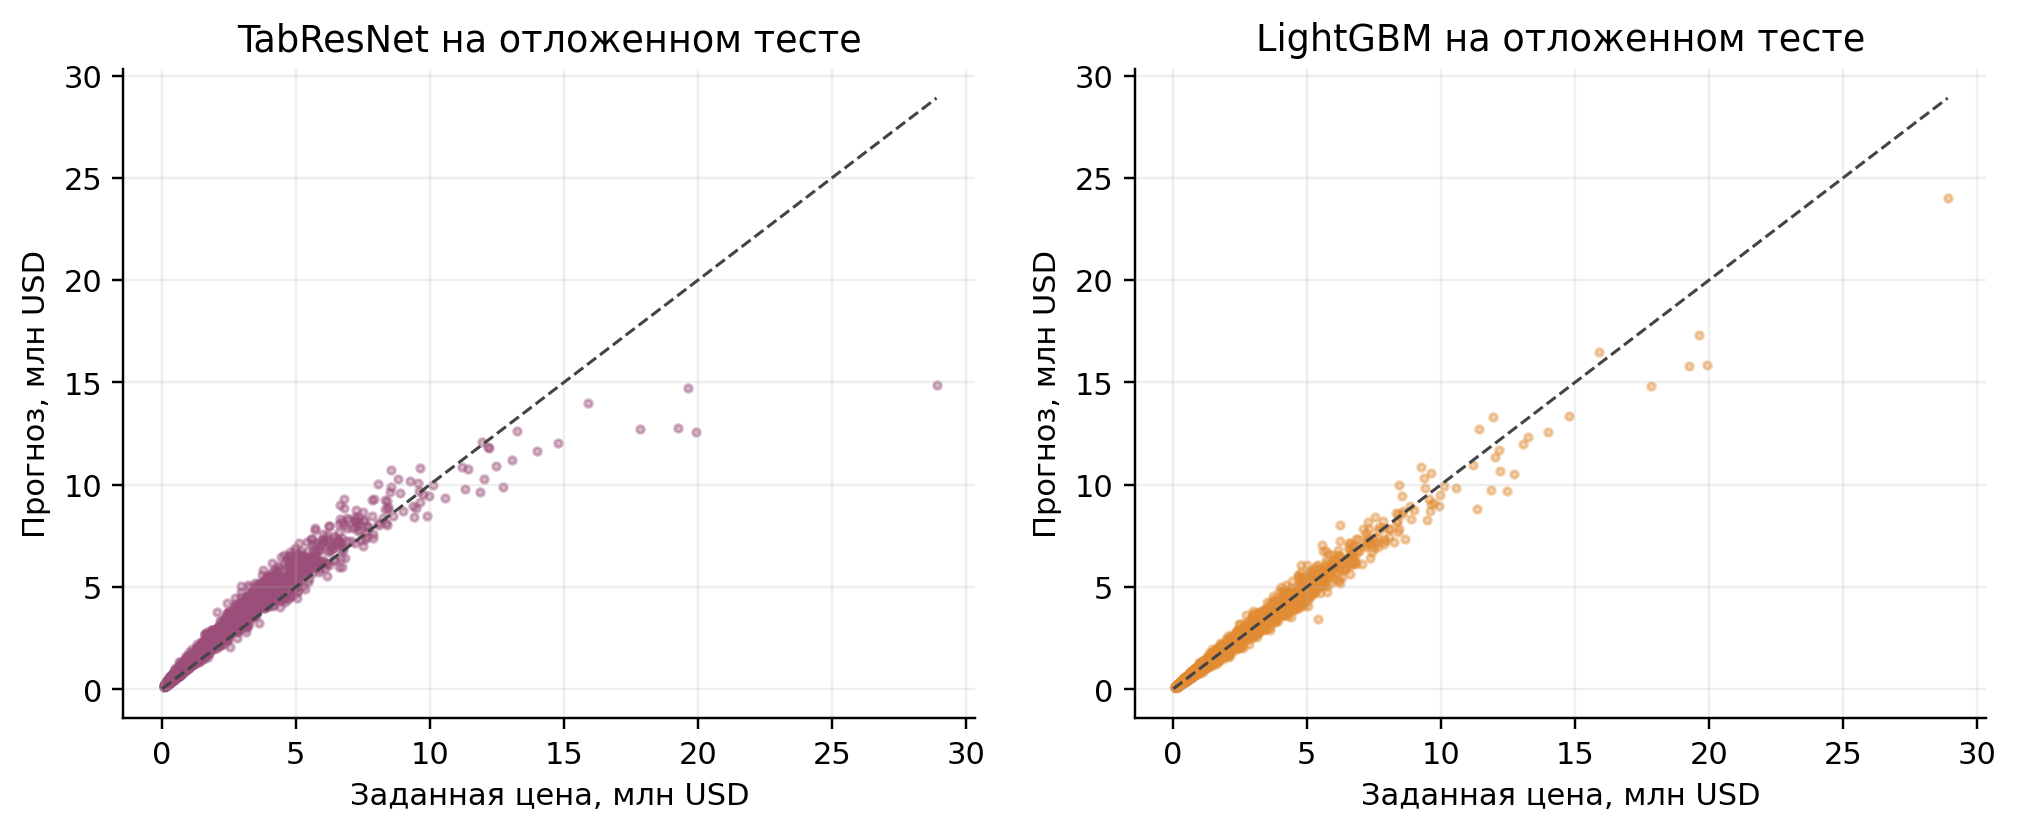

In [3]:
metrics = pd.read_csv(OUT / 'metrics.csv')
test = metrics[(metrics['split']=='test') & (metrics['seed']==42)].copy()
chosen = test[test.apply(lambda r: r['target']==selection['target_per_family'][r['family']], axis=1)]
display(chosen[['family','target','n','MAE_USD','RMSE_USD','MAPE_pct','R2','within20_pct']].round(3))
display(test[['family','target','MAE_USD','RMSE_USD','MAPE_pct','R2']].round(3))
display(Image(filename=str(OUT / 'figures/02_comparison.png')))
display(Image(filename=str(OUT / 'figures/04_predictions.png')))


## Повторные инициализации нейросетей
Среднее и стандартное отклонение по seeds 42, 43 и 44. Выбор лучшего seed по тесту не выполняется.

MAE_USD            MAPE_pct            R2       
                        mean        std     mean    std   mean    std
family    target                                                     
MLP       total   678924.931  30574.549   40.257  2.055  0.754  0.031
          unit    569557.880  45156.146   36.413  1.587  0.834  0.038
TabResNet total   491784.551  66833.206   34.237  3.191  0.877  0.026
          unit    483063.792  57713.613   32.715  3.126  0.886  0.025

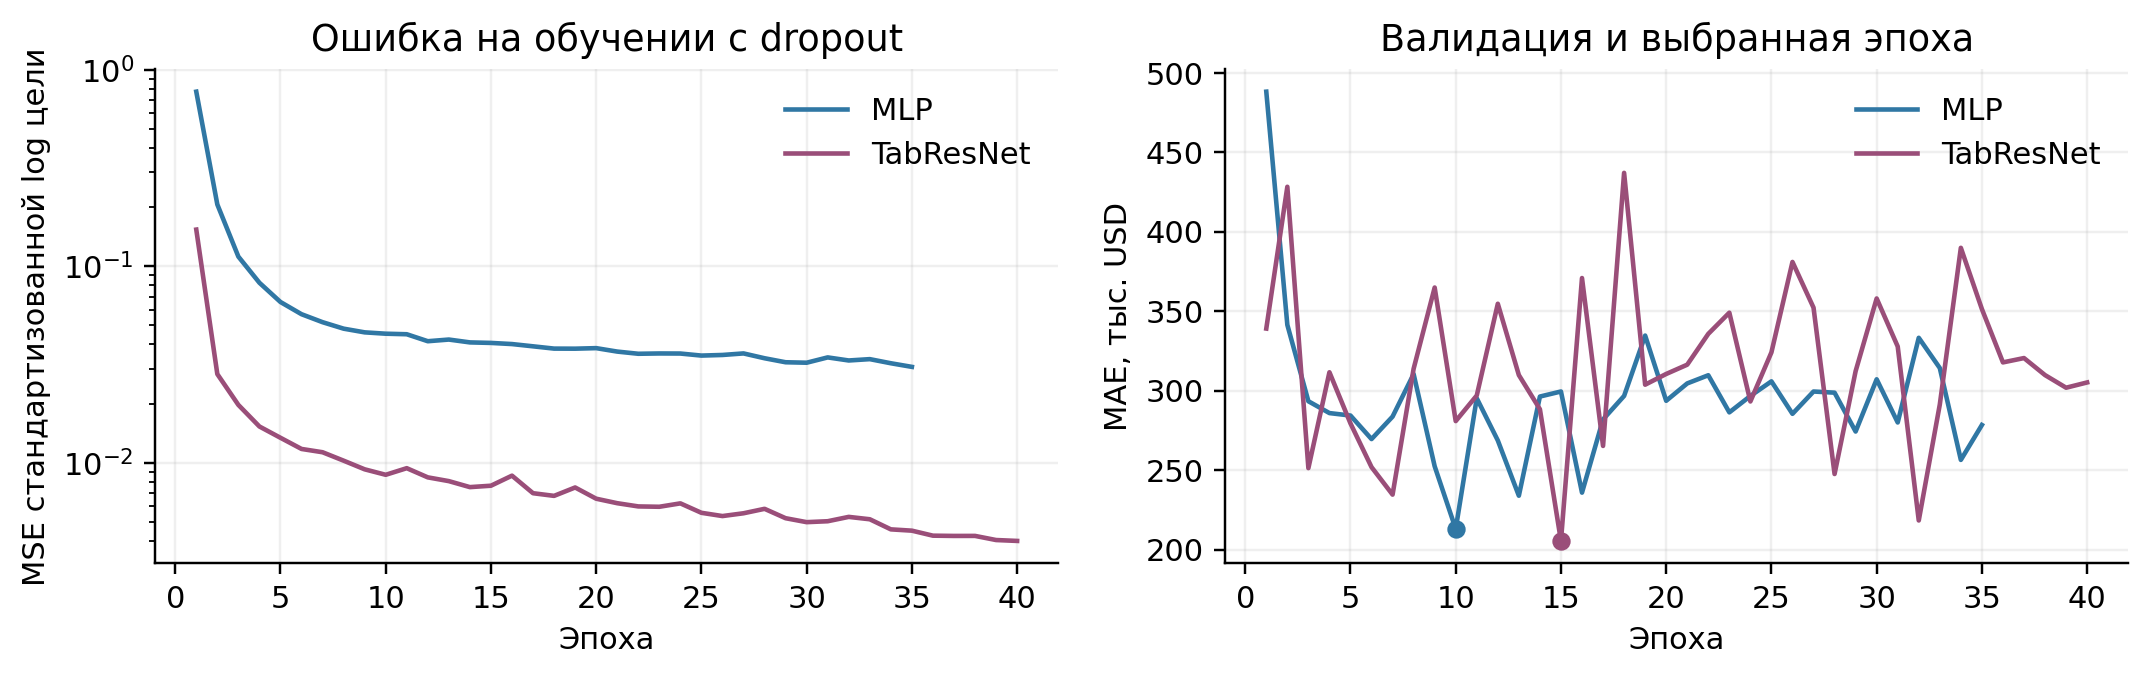

In [4]:
neural = metrics[(metrics['split']=='test') & metrics.family.isin(['MLP','TabResNet'])]
display(neural.groupby(['family','target'])[['MAE_USD','MAPE_pct','R2']].agg(['mean','std']).round(3))
display(Image(filename=str(OUT / 'figures/03_learning.png')))


## Ошибки входов
По отдельности: площадь ±30% у p строк, замена view у p строк, пропуски в площади и времени до метро по p строк каждого поля. 10 одинаковых для всех моделей масок на уровень. Истинные цены сохраняются. Для P/A восстановление полной цены использует наблюдаемую, в том числе повреждённую, площадь.

MAE_USD           relative_growth_pct      
                           mean       std                mean   std
family       kind                                                  
LightGBM     area     174394.52   2854.89               24.66  2.04
             missing  354380.97  11258.32              153.33  8.05
             view     166961.52   2884.37               19.35  2.06
MLP          area     546272.01   3715.45                2.15  0.69
             missing  666279.16   9425.57               24.59  1.76
             view     552342.66   3594.37                3.28  0.67
Median       area     842953.68   1472.93                0.58  0.18
             missing  952973.45   4258.10               13.71  0.51
             view     838104.97      0.00                0.00  0.00
RandomForest area     195556.08   2841.23               18.69  1.72
             missing  369763.46  10359.53              124.42  6.29
             view     179210.14   2002.84                8.77  1.22
Ridge        area     969686.59   3784.19                0.18  0.39
             missing  964062.20   6846.44               -0.40  0.71
             view     987476.58   4523.97                2.02  0.47
TabResNet    area     422707.40   2412.79                1.80  0.58
             missing  564073.21   9111.12               35.84  2.19
             view     434863.60   2651.97                4.73  0.64

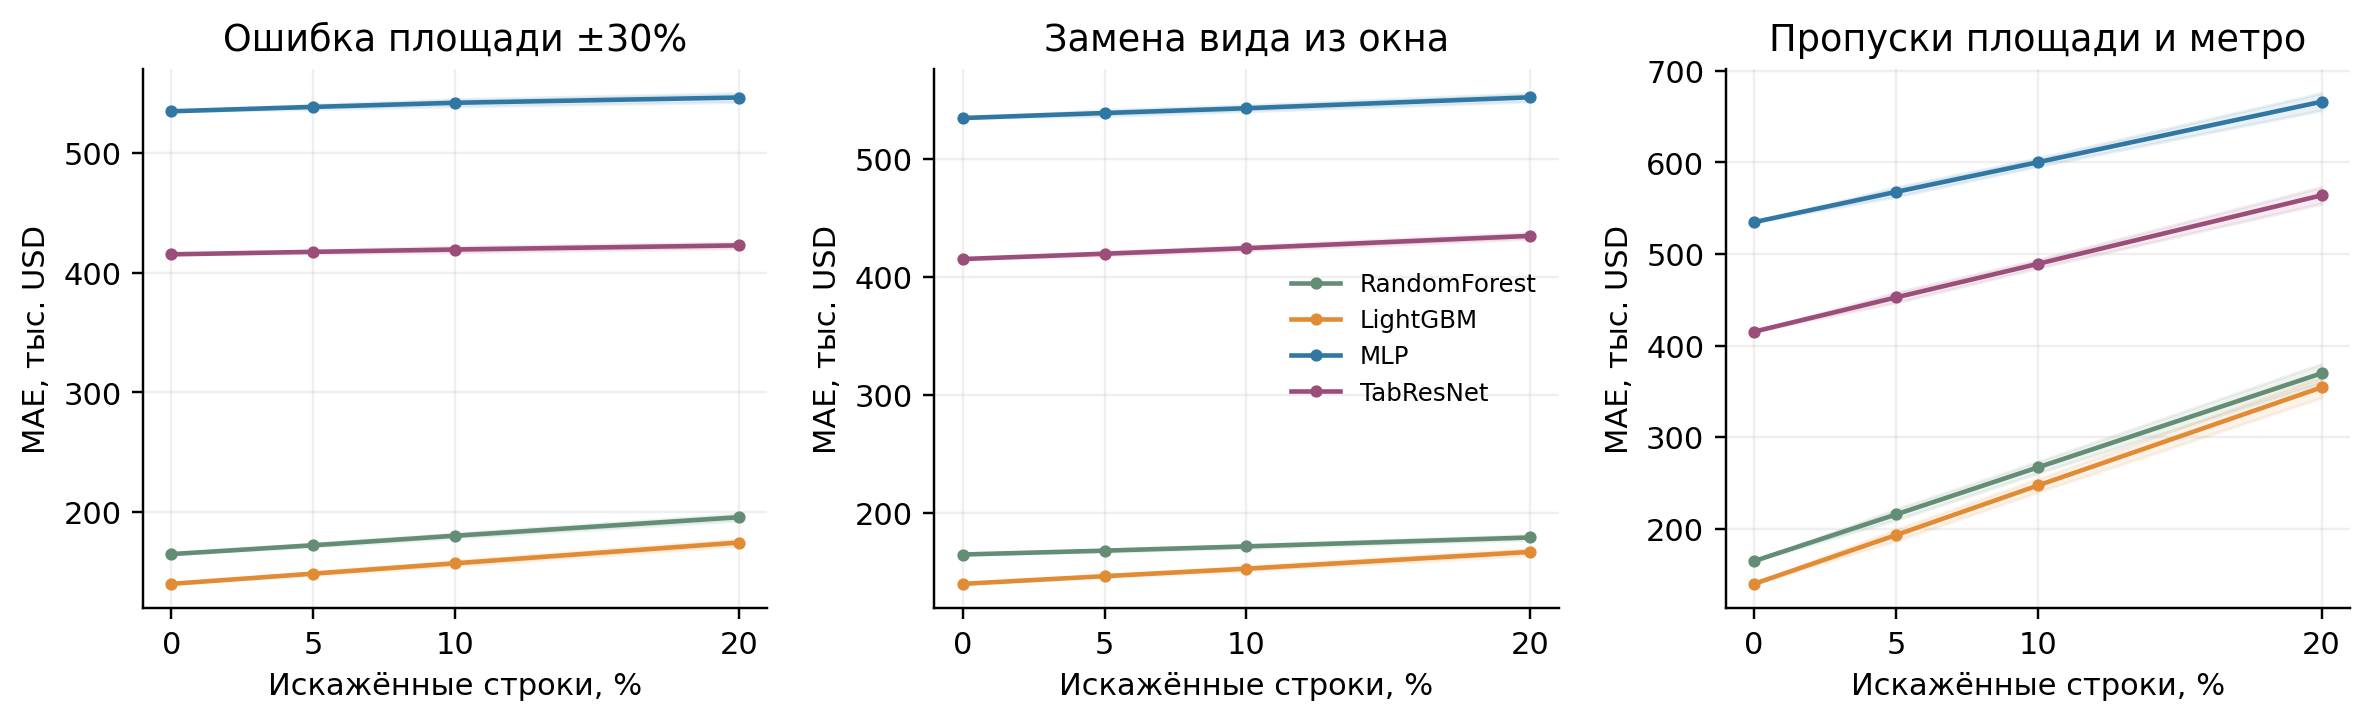

In [5]:
inputs = pd.read_csv(OUT / 'robustness_inputs_runs.csv')
display(inputs[inputs.share==0.2].groupby(['family','kind'])[['MAE_USD','relative_growth_pct']].agg(['mean','std']).round(2))
display(Image(filename=str(OUT / 'figures/05_input_noise.png')))


## Ошибки обучающих цен
У p строк train цена умножается на U[0.5, 1.5]. Чистая validation и правило ранней остановки сохраняются. Три парных повтора; baseline для каждого seed считается отдельно.

MAE_USD            relative_growth_pct       
                         mean        std                mean    std
family       share                                                 
LightGBM     0.00   139662.36     290.83                0.00   0.00
             0.05   143879.09    2045.15                3.02   1.48
             0.10   144823.93     411.88                3.70   0.50
             0.20   152655.21    3425.65                9.31   2.68
MLP          0.00   569557.88   45156.15                0.00   0.00
             0.05   584199.23   23292.68                2.86   6.42
             0.10   599855.36  114268.02                4.72  11.51
             0.20   578240.52   93899.70                1.14   8.85
RandomForest 0.00   164551.70     224.55               -0.00   0.00
             0.05   171678.52    2675.90                4.33   1.72
             0.10   174272.48    3186.00                5.91   1.96
             0.20   183096.12    3460.79               11.27   2.19
Ridge        0.00   967917.91       0.00                0.00   0.00
             0.05   981325.28   20312.93                1.39   2.10
             0.10   981672.16   18616.00                1.42   1.92
             0.20   988239.33   10799.14                2.10   1.12
TabResNet    0.00   491784.55   66833.21                0.00   0.00
             0.05   439943.96  100596.65              -10.92  13.11
             0.10   458413.82   23417.36               -5.99   8.90
             0.20   456890.99   91276.86               -6.12  19.99

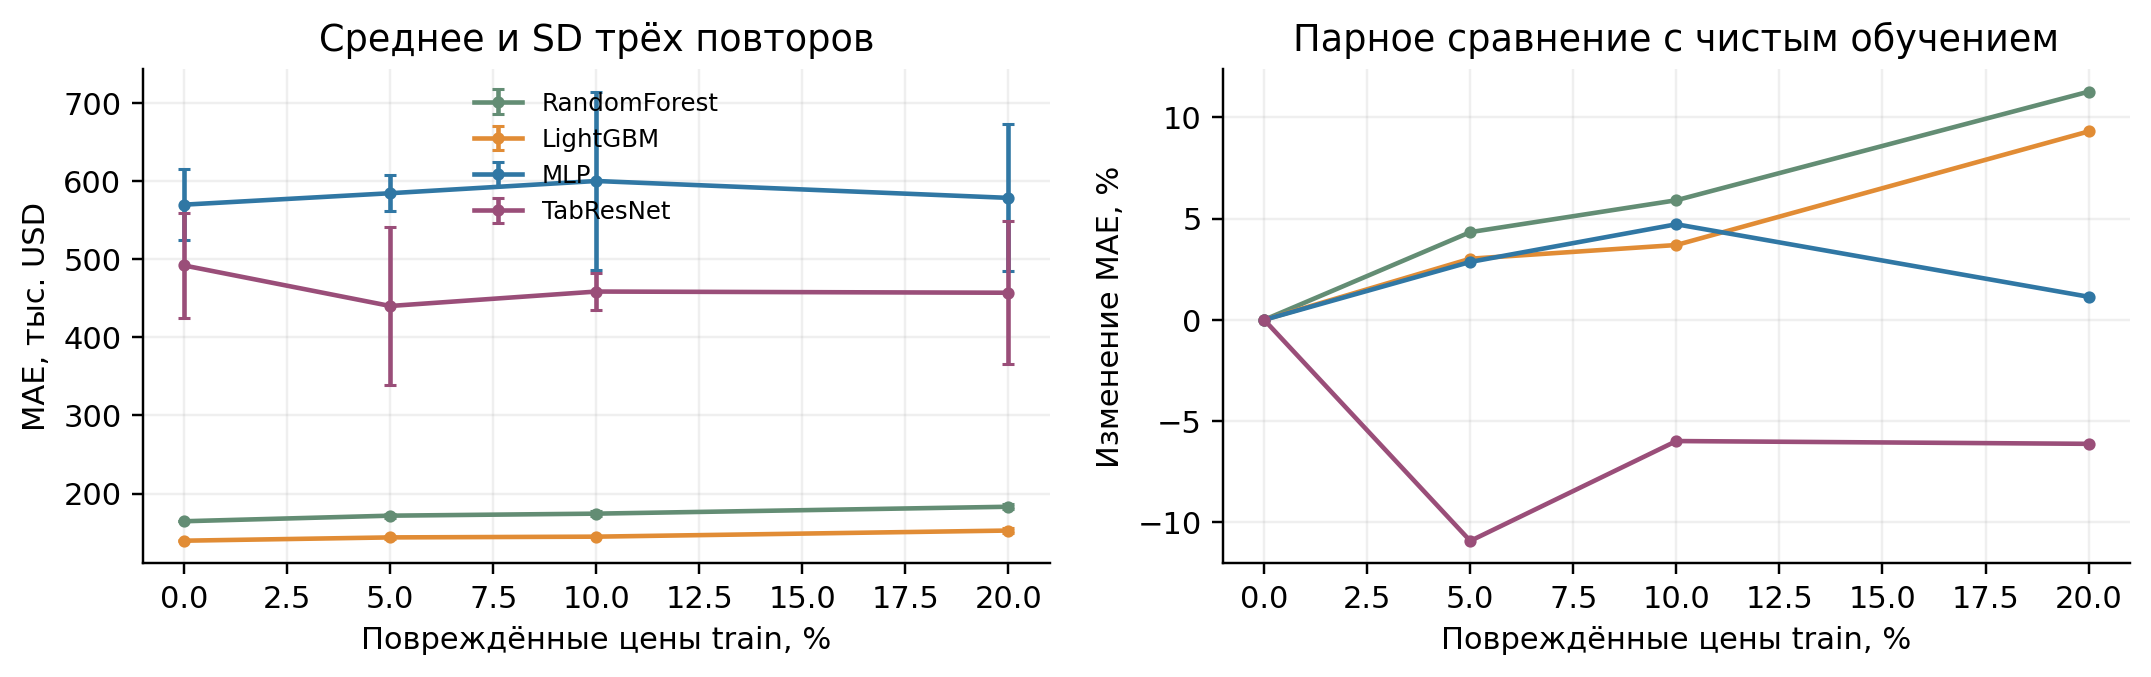

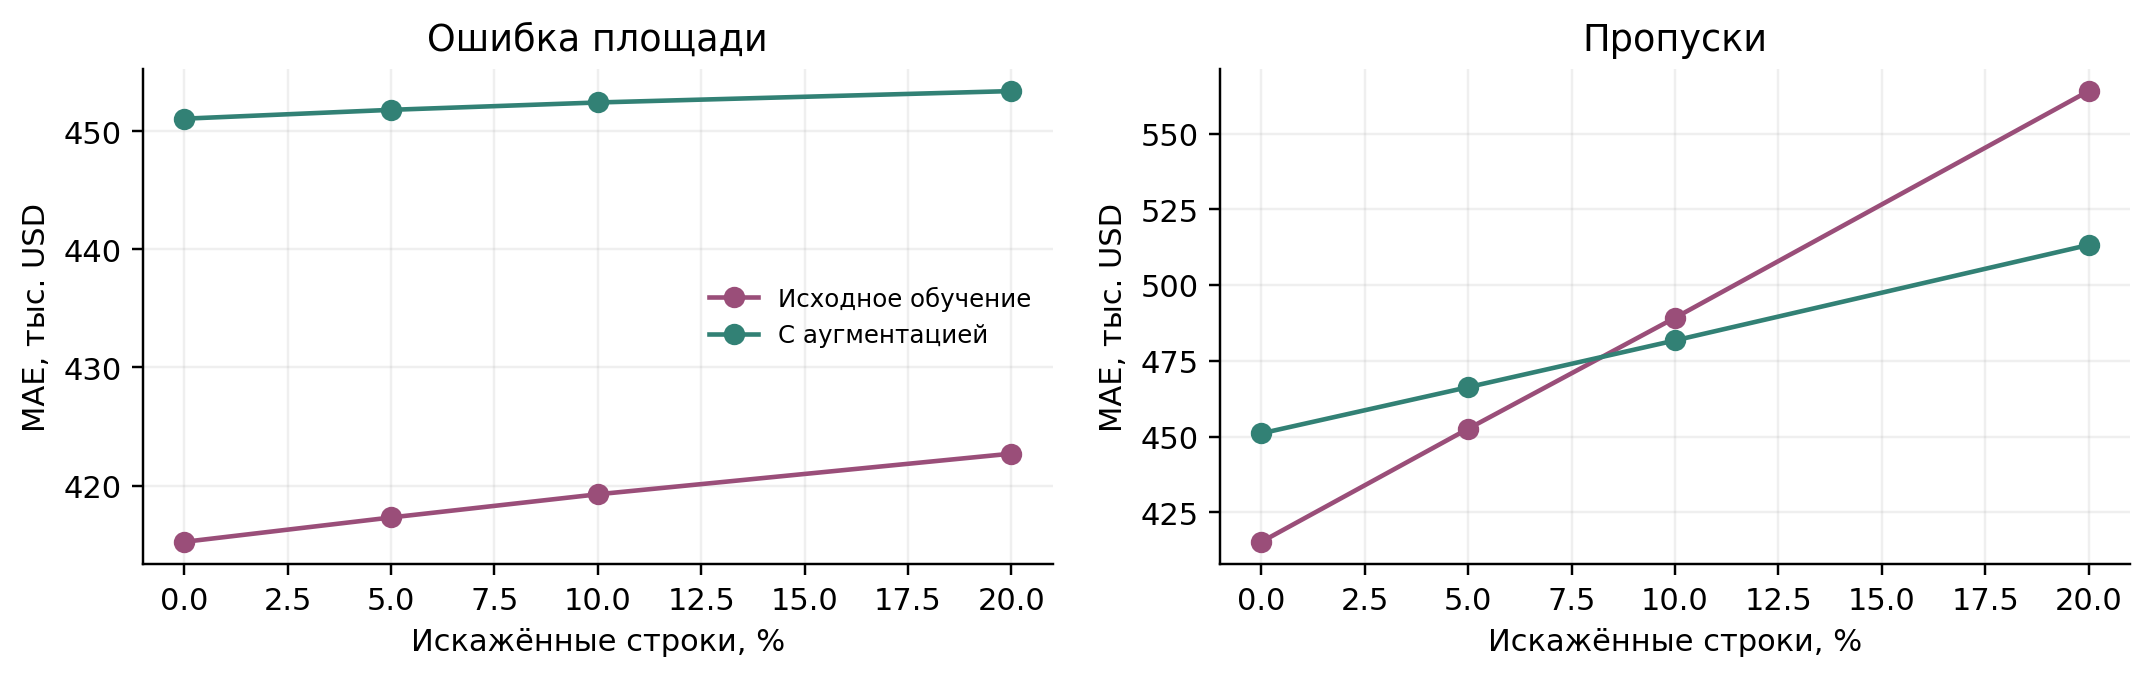

In [6]:
labels = pd.read_csv(OUT / 'robustness_labels_runs.csv')
display(labels.groupby(['family','share'])[['MAE_USD','relative_growth_pct']].agg(['mean','std']).round(2))
display(Image(filename=str(OUT / 'figures/06_label_noise.png')))
display(Image(filename=str(OUT / 'figures/09_augmentation.png')))


## Неопределённость и альтернативные проверки
Bootstrap выбирает целые тестовые проекты и сравнивает фиксированные модели. Групповой holdout проверяет новые проекты и смешивает даты. Строгая хронология меняет объём и покрытие train; результаты не заменяют основной benchmark.

In [7]:
display(pd.read_csv(OUT / 'bootstrap_intervals.csv').round(2))
display(pd.read_csv(OUT / 'group_holdout_metrics.csv').round(3))
display(pd.read_csv(OUT / 'strict_chronology_metrics.csv').round(3))
display(pd.read_csv(OUT / 'context_ablation.csv').round(3))


,metric,family,point,low,high,cluster,clusters,repeats
0,MAE_USD,Ridge,967917.91,867844.06,1075127.71,project_id,172,2000
1,MAE_USD,LightGBM,139891.06,119723.32,159618.69,project_id,172,2000
2,MAE_USD,TabResNet,415240.05,373443.89,456993.81,project_id,172,2000
3,paired_MAE_difference_USD,TabResNet minus LightGBM,275348.99,249184.67,302711.12,project_id,172,2000


,family,target,n_train,n_val,n_test,projects_train,projects_val,projects_test,n,MAE_USD,RMSE_USD,MAPE_pct,R2,within20_pct,MAE_USD_m2
0,Ridge,total,8296,1864,1840,120,26,26,1840,311027.942,633129.747,20.718,0.894,67.120,1640.063
1,LightGBM,unit,8296,1864,1840,120,26,26,1840,299999.570,626643.894,20.150,0.896,71.685,1577.927
2,TabResNet,total,8296,1864,1840,120,26,26,1840,238544.207,450184.107,16.713,0.946,77.120,1230.356


,family,target,removed,n_train,n_val,n_test,train_projects,test_unseen_projects,n,MAE_USD,RMSE_USD,MAPE_pct,R2,within20_pct,MAE_USD_m2
0,Ridge,total,4611,2496,1920,2973,114,57,2973,656698.583,1066708.339,42.772,0.746,23.882,2979.012
1,LightGBM,unit,4611,2496,1920,2973,114,57,2973,217689.576,550674.609,10.497,0.932,86.714,926.562
2,TabResNet,total,4611,2496,1920,2973,114,57,2973,436664.812,769734.025,34.161,0.868,32.728,2387.481


,family,target,n,MAE_USD,RMSE_USD,MAPE_pct,R2,within20_pct,MAE_USD_m2
0,LightGBM,unit,2984,419225.453,693010.001,21.263,0.892,42.326,1825.750
1,TabResNet,total,2984,296531.227,579783.889,18.898,0.925,53.854,1489.247


## Интерпретация и вычислительные сценарии
Групповая permutation importance рассчитывается на validation. Метод изменения одного входа связан с подходом Ясницких, но реакция функции модели не является причинным эффектом.

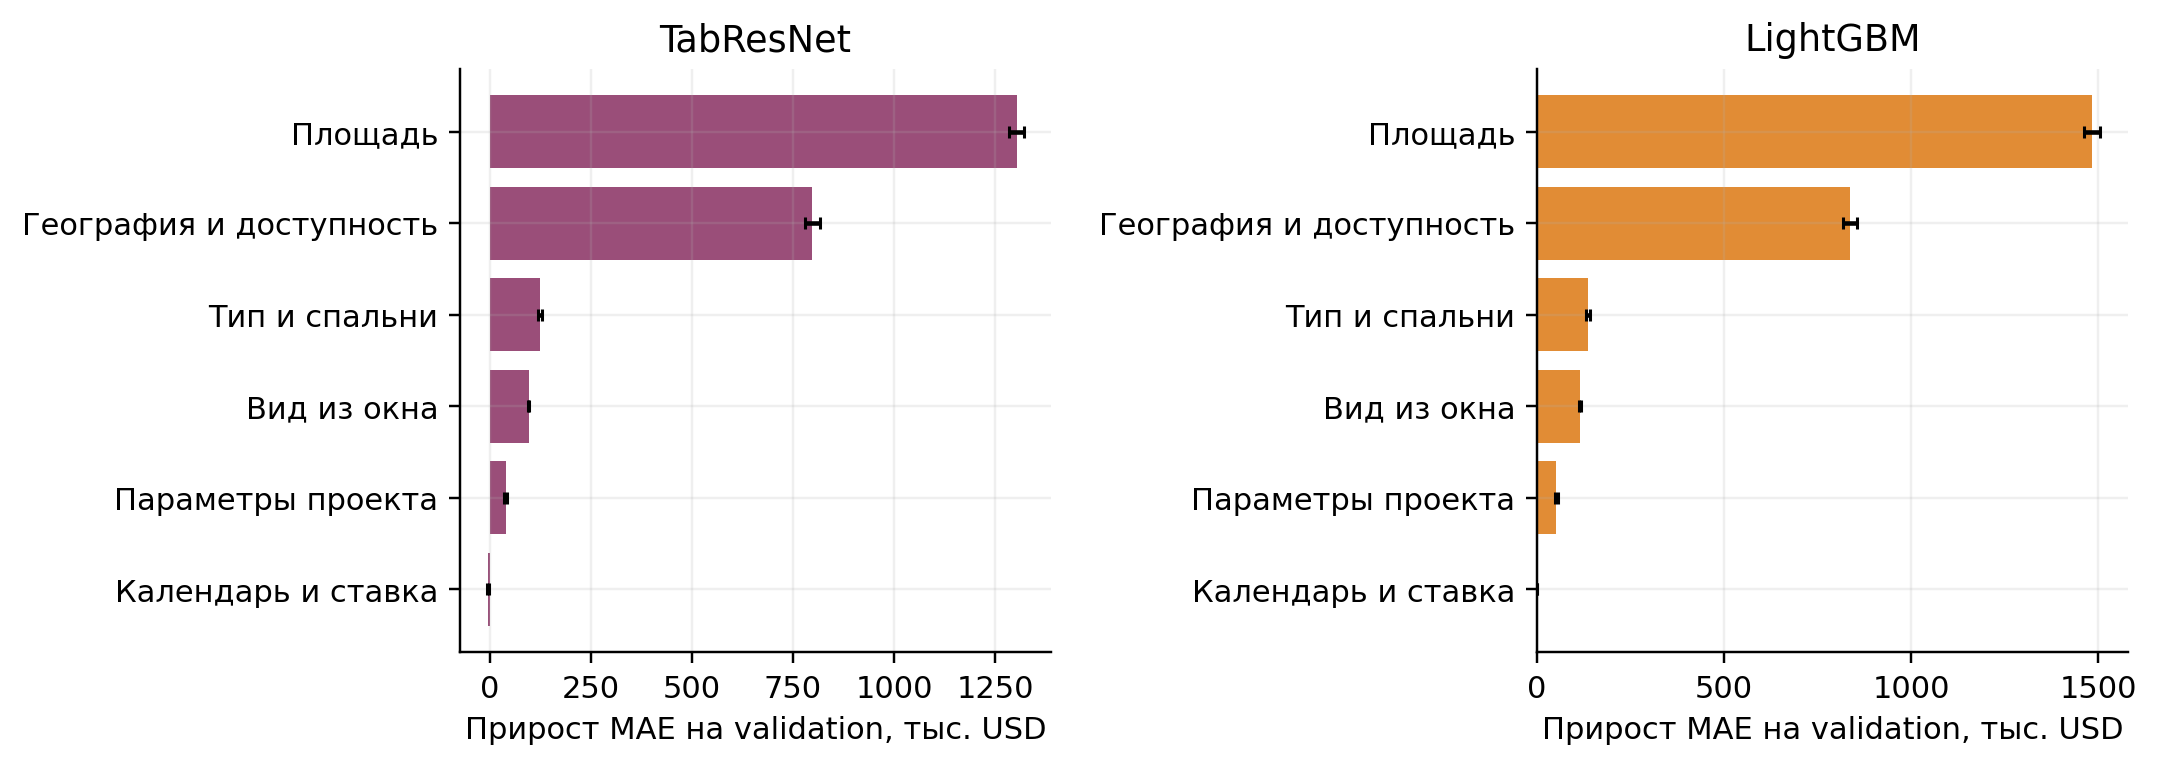

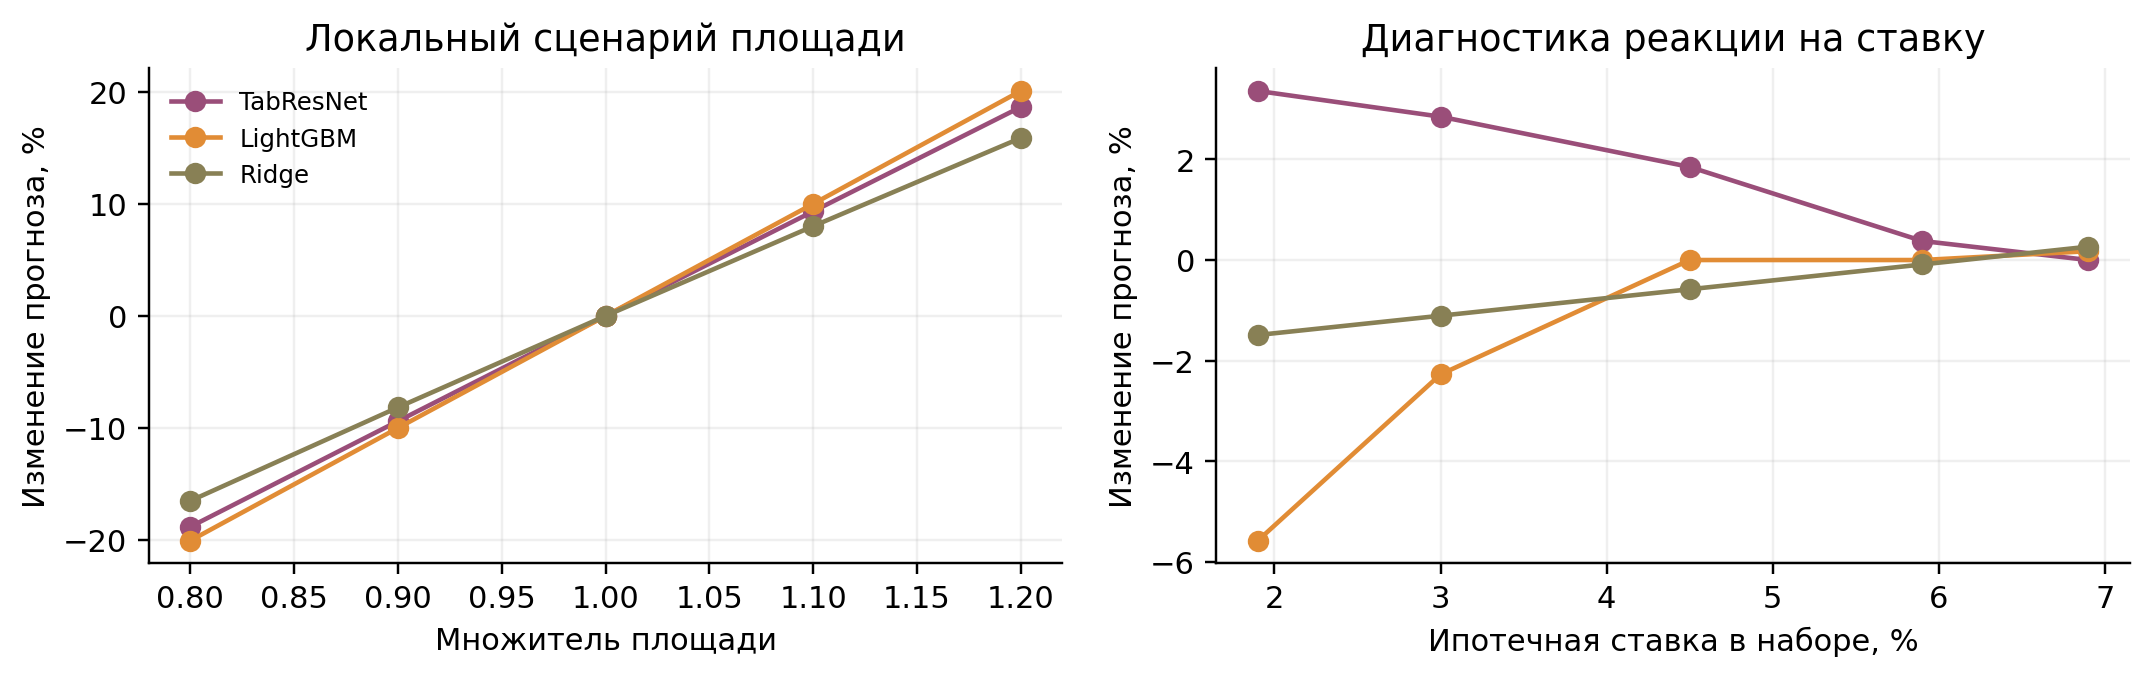

,family,feature,value,median_prediction_usd,median_paired_change_pct,outside_train_range_pct
0,Ridge,area_m2,0.8,1133344.318,-16.503,1.00
1,Ridge,area_m2,0.9,1246545.042,-8.164,0.50
2,Ridge,area_m2,1.0,1357353.661,0.000,0.00
3,Ridge,area_m2,1.1,1466055.198,8.008,0.25
4,Ridge,area_m2,1.2,1572875.382,15.878,0.50
5,Ridge,mortgage_rate_at_listing,1.9,1335373.800,-1.489,0.00
6,Ridge,mortgage_rate_at_listing,3.0,1340568.981,-1.106,0.00
7,Ridge,mortgage_rate_at_listing,4.5,1347686.494,-0.581,0.00
8,Ridge,mortgage_rate_at_listing,5.9,1354364.456,-0.088,0.00
9,Ridge,mortgage_rate_at_listing,6.9,1359153.197,0.265,0.00


In [8]:
display(Image(filename=str(OUT / 'figures/07_importance.png')))
display(Image(filename=str(OUT / 'figures/08_scenarios.png')))
display(pd.read_csv(OUT / 'scenarios.csv').round(3))


## Применение сохранённой модели
Три демонстрационные строки взяты из исходного набора и не являются новым тестом. Поля истинной цены и ценовых производных убраны из входа.

In [9]:
import joblib
family = selection['best_overall']
target = selection['target_per_family'][family]
model = joblib.load(OUT / 'models' / f'{family}_{target}_42.joblib')
demo = pd.read_csv(ROOT / 'data/off_plan.csv').head(3).drop(columns=['price_usd','price_per_sqft_usd','price_per_m2_usd'])
forecast = demo[['id','date_listed','community','area_m2']].copy()
forecast['predicted_price_usd'] = model.predict(demo)
display(forecast.round(2))


,id,date_listed,community,area_m2,predicted_price_usd
0,O000001,2025-02-22,Dubai Production City,62.4,207082.90
1,O000002,2021-03-19,The Meadows,555.0,3531623.33
2,O000003,2021-02-16,Jumeirah Park,236.8,1419378.76


## Проверки сохранённых результатов
Проверяются временные границы, отсутствие утечки цены в признаки, обучение предобработки только на train, правила повреждения и пересчёт метрик из индивидуальных прогнозов.

In [10]:
for command in [
    [sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-v'],
    [sys.executable, 'src/verify_results.py'],
]:
    completed = subprocess.run(command, cwd=ROOT, text=True, capture_output=True, check=True)
    print(completed.stdout)
    print(completed.stderr)



test_corruption_is_exact_nested_and_leaves_truth (test_protocol.ProtocolTests.test_corruption_is_exact_nested_and_leaves_truth) ... ok
test_holdouts_have_no_rows_or_dates_in_common (test_protocol.ProtocolTests.test_holdouts_have_no_rows_or_dates_in_common) ... ok
test_preprocessing_does_not_refit_on_future (test_protocol.ProtocolTests.test_preprocessing_does_not_refit_on_future) ... ok
test_target_and_ids_cannot_change_feature_matrix (test_protocol.ProtocolTests.test_target_and_ids_cannot_change_feature_matrix) ... ok
test_unit_price_prediction_uses_observed_area (test_protocol.ProtocolTests.test_unit_price_prediction_uses_observed_area) ... ok

----------------------------------------------------------------------
Ran 5 tests in 0.245s

OK

PASS source hash; frozen validation selection; 40 metric groups; disjoint splits; 540 input-noise runs; 60 label-noise records




## Полный повтор эксперимента
Сохранённые результаты доступны сразу. Чтобы заново обучить все модели и повторы, измените `RUN_FULL_EXPERIMENT` на `True`. Требуются зависимости из `requirements.txt`. В Colab сначала распакуйте весь архив в рабочий каталог; одной загрузки ipynb недостаточно.

In [11]:
RUN_FULL_EXPERIMENT = False
if RUN_FULL_EXPERIMENT:
    subprocess.run([sys.executable, 'src/experiment.py', '--stage', 'all'], cwd=ROOT, check=True)
    subprocess.run([sys.executable, 'src/plots.py'], cwd=ROOT, check=True)
    subprocess.run([sys.executable, 'src/verify_results.py'], cwd=ROOT, check=True)
else:
    print('Используются сохранённые результаты. Полный пересчёт выключен.')


Используются сохранённые результаты. Полный пересчёт выключен.


## Выводы
На временном тесте LightGBM с удельной целью превосходит проверенные нейросети. Остаточная сеть при заранее заданном seed 42 лучше выбранной MLP, но чувствительна к позднему периоду; результаты по трём seed показывают разброс. На новых проектах порядок моделей меняется. Ошибки площади и особенно её пропуски ухудшают полную денежную оценку, поэтому устойчивость рассматривается совместно с исходной точностью. Подробная аргументация и ссылки на Ясницкого находятся в `report/project_report.docx` и `report/decision_log.md`.